# Tabela de Métricas Comparativa Completa

In [3]:
import os
import sys
import numpy as np
import pandas as pd
from stable_baselines3 import PPO, SAC, DDPG

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from envs.sghaul_env import SGHaulEnv

def extrair_metricas_artigo(env, model=None, acao_estatica=None, episodios=10):
    resultados = {
        'throughput_urllc': [], 'throughput_embb': [], 'throughput_mmtc': [],
        'sla_urllc': [], 'sla_embb': [], 'sla_mmtc': [],
        'lat_media_urllc': [], 'lat_p99_urllc': [], 'jitter_urllc': [],
        'lat_media_mmtc': []
    }
    
    for ep in range(episodios):
        obs, info = env.reset(seed=(2000 + ep))
        done = False
        
        ep_th_urllc, ep_th_embb, ep_th_mmtc = 0.0, 0.0, 0.0
        ep_viol_urllc, ep_tot_urllc = 0, 0
        ep_viol_embb, ep_tot_embb = 0, 0
        ep_viol_mmtc, ep_tot_mmtc = 0, 0
        ep_latencias_urllc = []
        ep_latencias_mmtc = []
        passos = 0
        
        while not done:
            if model is not None:
                action, _ = model.predict(obs, deterministic=True)
            else:
                action = acao_estatica
                
            obs, reward, terminated, truncated, info = env.step(action)
            
            ep_th_urllc += info.get('throughput_urllc_mbps', 0.0) * 1000.0
            ep_th_embb += info.get('throughput_embb_mbps', 0.0) * 1000.0
            ep_th_mmtc += info.get('throughput_mmtc_mbps', 0.0) * 1000.0
            
            ep_viol_urllc += info.get('violacoes_uc16', 0)
            ep_tot_urllc += info.get('total_pacotes_uc16', 0)
            
            ep_viol_embb += info.get('violacoes_uc3', 0)
            ep_tot_embb += info.get('total_pacotes_uc3', 0)
            
            ep_viol_mmtc += info.get('violacoes_mmtc', 0)
            ep_tot_mmtc += info.get('total_pacotes_mmtc', 0)
            
            lat_urllc = info.get('avg_latency_uc16', 0.0)
            if lat_urllc > 0: ep_latencias_urllc.append(lat_urllc)
                
            lat_mmtc = info.get('avg_latency_mmtc', 0.0)
            if lat_mmtc > 0: ep_latencias_mmtc.append(lat_mmtc)
                
            passos += 1
            done = terminated or truncated

        resultados['throughput_urllc'].append(ep_th_urllc / passos if passos > 0 else 0)
        resultados['throughput_embb'].append(ep_th_embb / passos if passos > 0 else 0)
        resultados['throughput_mmtc'].append(ep_th_mmtc / passos if passos > 0 else 0)
        
        resultados['sla_urllc'].append((1.0 - (ep_viol_urllc / ep_tot_urllc))*100 if ep_tot_urllc > 0 else 0.0)
        resultados['sla_embb'].append((1.0 - (ep_viol_embb / ep_tot_embb))*100 if ep_tot_embb > 0 else 0.0)
        resultados['sla_mmtc'].append((1.0 - (ep_viol_mmtc / ep_tot_mmtc))*100 if ep_tot_mmtc > 0 else 0.0)
        
        if ep_latencias_urllc:
            resultados['lat_media_urllc'].append(np.mean(ep_latencias_urllc))
            resultados['lat_p99_urllc'].append(np.percentile(ep_latencias_urllc, 99))
            resultados['jitter_urllc'].append(np.std(ep_latencias_urllc))
        else:
            resultados['lat_media_urllc'].append(np.nan)
            resultados['lat_p99_urllc'].append(np.nan)
            resultados['jitter_urllc'].append(np.nan)
            
        if ep_latencias_mmtc:
            resultados['lat_media_mmtc'].append(np.mean(ep_latencias_mmtc))
        else:
            resultados['lat_media_mmtc'].append(np.nan)

    tabela_final = {}
    for chave, valores in resultados.items():
        valores_validos = [v for v in valores if not np.isnan(v)]
        if not valores_validos:
            tabela_final[chave] = "Falha (0 pkts)"
        else:
            tabela_final[chave] = f"{np.mean(valores_validos):.2f} ± {np.std(valores_validos):.2f}"
            
    return tabela_final

# ==========================================
# EXECUÇÃO E CRIAÇÃO DO DATAFRAME COMPARATIVO
# ==========================================
env = SGHaulEnv()
base_path = r"C:\Users\adriely\Desktop\SGHaul_DRL_Project_2\models"

# Carregando os modelos
model_ppo = PPO.load(f"{base_path}\\ppo_sghaul_slicing_3fatias.zip", env=env)
model_sac = SAC.load(f"{base_path}\\sac_sghaul_slicing_3fatias.zip", env=env)
model_ddpg = DDPG.load(f"{base_path}\\ddpg_sghaul_slicing_3fatias.zip", env=env)

res_ppo = extrair_metricas_artigo(env, model=model_ppo)
res_sac = extrair_metricas_artigo(env, model=model_sac)
res_ddpg = extrair_metricas_artigo(env, model=model_ddpg)

# Baselines Estáticos via Softmax (Ações Logits)
res_estatico_eq = extrair_metricas_artigo(env, acao_estatica=np.array([0.0, 0.0, 0.0])) # 33% cada
res_estatico_urllc = extrair_metricas_artigo(env, acao_estatica=np.array([2.0, 0.0, 0.0])) # Foco URLLC
res_estatico_embb = extrair_metricas_artigo(env, acao_estatica=np.array([0.0, 2.0, 0.0])) # Foco eMBB

df_tcc = pd.DataFrame(
    [res_ppo, res_sac, res_ddpg, res_estatico_eq, res_estatico_urllc, res_estatico_embb], 
    index=["DRL PPO", "DRL SAC", "DRL DDPG", "Static (33% all)", "Static (Priority URLLC)", "Static (Priority eMBB)"]
)

df_tcc.columns = [
    "Thr. URLLC (Kbps)", "Thr. eMBB (Kbps)", "Thr. mMTC (Kbps)", 
    "SLA URLLC (%)", "SLA eMBB (%)", "SLA mMTC (%)", 
    "Avg Lat. URLLC (ms)", "p99 Lat. URLLC (ms)", "Jitter URLLC (ms)",
    "Avg Lat. mMTC (ms)"
]

display(df_tcc)

C:\Users\adriely\AppData\Roaming\Python\Python313\site-packages\gymnasium\spaces\box.py:231: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
C:\Users\adriely\AppData\Roaming\Python\Python313\site-packages\gymnasium\spaces\box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


,Thr. URLLC (Kbps),Thr. eMBB (Kbps),Thr. mMTC (Kbps),SLA URLLC (%),SLA eMBB (%),SLA mMTC (%),Avg Lat. URLLC (ms),p99 Lat. URLLC (ms),Jitter URLLC (ms),Avg Lat. mMTC (ms)
DRL PPO,83.49 ± 60.00,1.03 ± 0.09,0.32 ± 0.39,100.00 ± 0.00,1.84 ± 1.18,99.66 ± 1.01,182.54 ± 6.75,250.10 ± 0.17,68.01 ± 12.71,860.97 ± 479.60
DRL SAC,110.61 ± 64.27,18.20 ± 9.36,0.53 ± 0.41,99.98 ± 0.02,38.58 ± 34.78,100.00 ± 0.00,181.42 ± 5.94,254.85 ± 3.94,61.06 ± 13.40,144.78 ± 48.22
DRL DDPG,85.74 ± 58.04,15.01 ± 7.94,0.61 ± 0.45,87.26 ± 15.49,71.20 ± 42.21,66.22 ± 36.69,271.25 ± 104.81,1605.84 ± 1681.66,289.54 ± 289.37,8012.33 ± 8920.39
Static (33% all),48.68 ± 4.79,10.20 ± 2.76,0.75 ± 0.58,99.95 ± 0.07,97.25 ± 3.49,100.00 ± 0.00,189.67 ± 0.93,271.00 ± 2.00,75.68 ± 2.88,156.74 ± 34.02
Static (Priority URLLC),58.89 ± 38.54,1.06 ± 0.13,0.42 ± 0.49,100.00 ± 0.00,2.80 ± 1.30,92.13 ± 15.25,185.55 ± 4.60,250.17 ± 0.50,71.92 ± 8.08,1541.64 ± 1493.11
Static (Priority eMBB),1.29 ± 0.07,15.62 ± 10.09,0.53 ± 0.47,0.12 ± 0.18,87.60 ± 18.95,90.99 ± 15.33,49156.56 ± 2298.93,96913.24 ± 1172.67,28478.16 ± 580.07,1740.74 ± 1888.75


# Gráfico de Convergência (PPO vs SAC vs DDPG)

Gerando gráfico Comparativo de Treinamento...


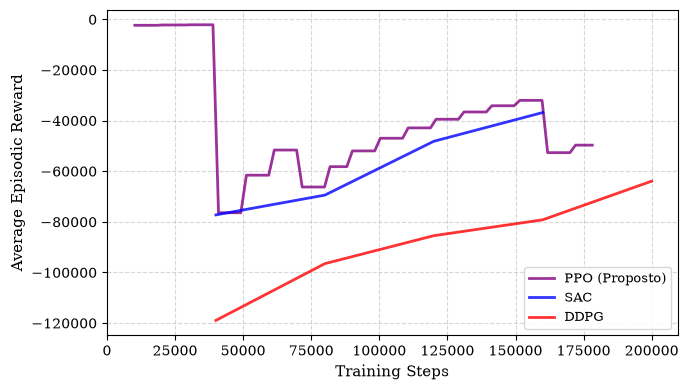

✅ Gráfico Comparativo salvo com sucesso!


In [4]:
import os
import glob
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

def extrair_dados_tb(tb_log_file):
    event_acc = EventAccumulator(tb_log_file)
    event_acc.Reload()
    scalar_tag = 'rollout/ep_rew_mean'
    if scalar_tag in event_acc.Tags()['scalars']:
        events = event_acc.Scalars(scalar_tag)
        return [e.step for e in events], [e.value for e in events]
    return [], []

print("Gerando gráfico Comparativo de Treinamento...")
base_log_dir = r"C:\Users\adriely\Desktop\SGHaul_DRL_Project_2\logs"

plt.rcParams['font.family'] = 'serif'
plt.figure(figsize=(7, 4))

cores = {"ppo": "purple", "sac": "blue", "ddpg": "red"}
nomes = {"ppo": "PPO (Proposto)", "sac": "SAC", "ddpg": "DDPG"}

for algo in ["ppo", "sac", "ddpg"]:
    pasta_algo = os.path.join(base_log_dir, f"{algo}_sghaul_tensorboard")
    arquivos_tb = glob.glob(os.path.join(pasta_algo, "**", "events.out.tfevents.*"), recursive=True)
    
    if arquivos_tb:
        caminho_recente = max(arquivos_tb, key=os.path.getctime)
        steps, rewards = extrair_dados_tb(caminho_recente)
        if steps:
            plt.plot(steps, rewards, color=cores[algo], linewidth=2.0, label=nomes[algo], alpha=0.8)

plt.xlabel("Training Steps", fontsize=11)
plt.ylabel("Average Episodic Reward", fontsize=11)
plt.tick_params(axis='both', which='major', labelsize=10)
plt.xlim(left=0)
plt.margins(x=0)

plt.legend(loc='lower right', fontsize=9, frameon=True, framealpha=0.9, edgecolor='lightgrey')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig("results/Comparative_Learning_Curve.pdf", dpi=300, bbox_inches='tight', pad_inches=0.02)
plt.show()
print("✅ Gráfico Comparativo salvo com sucesso!")

# Gráficos Temporais (Com as 3 fatias)

Gerando gráficos definitivos de 3 Fatias (Modelo PPO)...


C:\Users\adriely\AppData\Roaming\Python\Python313\site-packages\gymnasium\spaces\box.py:231: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
C:\Users\adriely\AppData\Roaming\Python\Python313\site-packages\gymnasium\spaces\box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


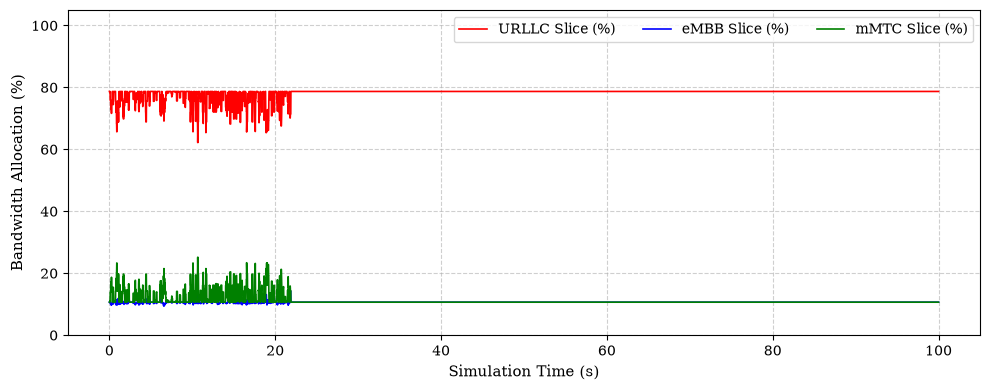

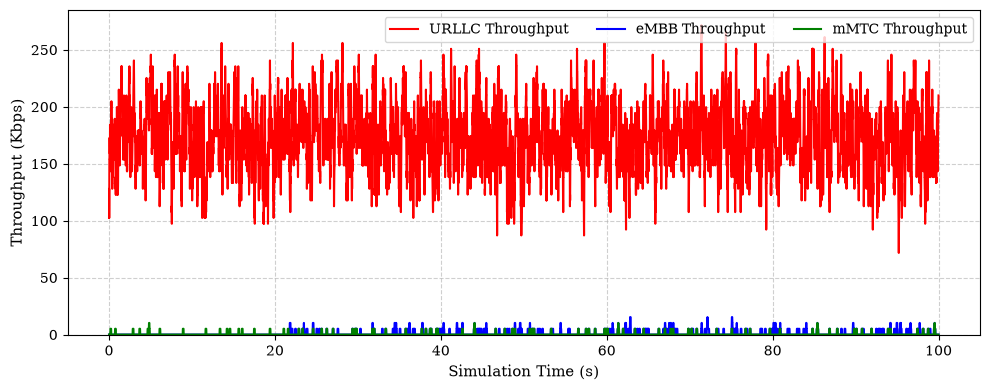

✅ Gráficos temporais de 3 fatias gerados!


In [5]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from envs.sghaul_env import SGHaulEnv

# Trava da Semente
seed_val = 83604
os.environ['PYTHONHASHSEED'] = str(seed_val)
random.seed(seed_val)
np.random.seed(seed_val)

print("Gerando gráficos definitivos de 3 Fatias (Modelo PPO)...")
env = SGHaulEnv()
caminho_modelo = r"C:\Users\adriely\Desktop\SGHaul_DRL_Project_2\models\ppo_sghaul_slicing_3fatias.zip"
model = PPO.load(caminho_modelo, env=env)

obs, info = env.reset(seed=seed_val) 

tempos = []
aloc_urllc, aloc_embb, aloc_mmtc = [], [], []
vazao_urllc, vazao_embb, vazao_mmtc = [], [], []

passo = 0
while True:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    
    tempos.append(passo * 0.01)
    
    # Replica o Softmax do ambiente para extrair as porcentagens corretas para o gráfico
    exp_action = np.exp(action)
    band_allocation = (exp_action / np.sum(exp_action)) * 100.0
    
    aloc_urllc.append(band_allocation[0])
    aloc_embb.append(band_allocation[1])
    aloc_mmtc.append(band_allocation[2])
        
    vazao_urllc.append(info.get('throughput_urllc_mbps', 0.0) * 1000.0)
    vazao_embb.append(info.get('throughput_embb_mbps', 0.0) * 1000.0)
    vazao_mmtc.append(info.get('throughput_mmtc_mbps', 0.0) * 1000.0)

    if terminated or truncated:
        break
    passo += 1

# Suavização para o gráfico macro
v_urllc_suave = pd.Series(vazao_urllc).rolling(window=10, min_periods=1).mean()
v_embb_suave = pd.Series(vazao_embb).rolling(window=10, min_periods=1).mean()
v_mmtc_suave = pd.Series(vazao_mmtc).rolling(window=10, min_periods=1).mean()

a_urllc_suave = pd.Series(aloc_urllc).rolling(window=10, min_periods=1).mean()
a_embb_suave = pd.Series(aloc_embb).rolling(window=10, min_periods=1).mean()
a_mmtc_suave = pd.Series(aloc_mmtc).rolling(window=10, min_periods=1).mean()

plt.rcParams['font.family'] = 'serif'
os.makedirs("results", exist_ok=True)

# 1. Gráfico de Alocação (Macro)
plt.figure(figsize=(10, 4)) 
plt.plot(tempos, a_urllc_suave, label='URLLC Slice (%)', color='red', linewidth=1.2)
plt.plot(tempos, a_embb_suave, label='eMBB Slice (%)', color='blue', linewidth=1.2)
plt.plot(tempos, a_mmtc_suave, label='mMTC Slice (%)', color='green', linewidth=1.2)
plt.xlabel("Simulation Time (s)", fontsize=11)
plt.ylabel("Bandwidth Allocation (%)", fontsize=11)
plt.ylim(0, 105) 
plt.legend(loc='upper right', fontsize=10, ncol=3)
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('results/temporal_allocation_3slices.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 2. Gráfico de Vazão (Macro)
plt.figure(figsize=(10, 4))
plt.plot(tempos, v_urllc_suave, label='URLLC Throughput', color='red', linewidth=1.5)
plt.plot(tempos, v_embb_suave, label='eMBB Throughput', color='blue', linewidth=1.5)
plt.plot(tempos, v_mmtc_suave, label='mMTC Throughput', color='green', linewidth=1.5)
plt.xlabel("Simulation Time (s)", fontsize=11)
plt.ylabel("Throughput (Kbps)", fontsize=11)
plt.ylim(bottom=-0.5) 
plt.legend(loc='upper right', fontsize=10, ncol=3)
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('results/temporal_throughput_3slices.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Gráficos temporais de 3 fatias gerados!")